# Problem Statement

## Predicting Hospital Readmission Risk for Diabetic Patients Using Machine Learning.

- This project focuses on predicting hospital readmission for diabetic patients using a real-world dataset containing over 100,000 patient records.

- The dataset includes patient demographics, medical history, laboratory results, medications, and treatment outcomes.

- The main objective is to build a machine learning model to classify whether a patient will be readmitted.

- The model helps identify patterns and key factors contributing to readmissions.

- Hospitals can take preventive measures such as better discharge planning and timely follow-ups.

- This helps reduce readmissions, improve patient outcomes, and optimize resources.

In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [119]:
df = pd.read_csv("diabetic_data.csv")

## Inspecting the dataset

In [120]:
df

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO


In [121]:
df.shape

(101766, 50)

#### The dataset has 101766 rows and 50 columns which means we have a large dataset suitable for supervised machine learning.

In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

#### The dataset contains 13 numerical features and 37 categorical features (string type). Therefore, extensive preprocessing such as encoding categorical variables, handling missing values, and feature transformation will be required before training machine learning models.

#### Columns with missing values :- 

##### max_glu_serum (5346 non-null), A1Cresult (17018 non-null)


#### Categorical columns :-

##### race, gender, age, weight, payer_code, medical_specialty, diag_1, diag_2, diag_3, max_glu_serum, A1Cresult, metformin, repaglinide, 

##### nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, 

##### troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-

##### rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted


#### Numerical columns :-

##### encounter_id, patient_nbr, admission_type_id, discharge_disposition_id, admission_source_id, time_in_hospital, num_lab_procedures, 

##### num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

#

### The target variable for supervised learning appears to be readmitted, which is a categorical column, so this is a classification problem.
### Overall, the dataset is a structured medical dataset with mixed data types, and it will require data cleaning, missing value handling, encoding of categorical variables, and feature selection before applying supervised learning algorithms.

In [123]:
df.describe(include="all")

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,101766,101766,101766,101766,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,6,3,10,10,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),?,NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,98569,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Inferences from df.describe(include="all")
##### For categorical features, the summary shows:
###### unique → number of unique categories
###### top → most frequent category
###### freq → frequency of most frequent category

##### For numerical features, the summary shows:
##### mean (average)
##### standard deviation
##### minimum value
##### 25%, 50%, 75% percentiles
##### maximum value


##### Some categorical columns have a dominant category (e.g., Caucasian, Female). Weight column contains missing values represented by "?". Average 

##### hospital stay is around 4 days. Some numerical features have large variation (e.g., number of lab procedures, number of medications). 

##### Percentiles help us understand data distribution and detect outliers

## Data Preprocessing

### Checking Unique Values of Features

In this step, we analyze the unique values present in each column of the dataset. This is an important part of data understanding and preprocessing, especially for categorical variables.

By examining unique values, we can:

* Identify categorical features and understand their possible values
* Detect inconsistencies such as unexpected categories or spelling variations
* Find placeholders for missing data (e.g., `"?"`, `"Unknown"`)
* Determine the type of encoding required (Label Encoding or One-Hot Encoding)
* Identify columns with too many unique values that may not be useful for modeling (e.g., IDs)

This step helps in planning the preprocessing pipeline effectively before applying machine learning algorithms.


In [124]:
for col in df.select_dtypes(include=['object','string']).columns:
    print(col, list(df[col].dropna().unique()) , '\n')

race ['Caucasian', 'AfricanAmerican', '?', 'Other', 'Asian', 'Hispanic'] 

gender ['Female', 'Male', 'Unknown/Invalid'] 

age ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)'] 

weight ['?', '[75-100)', '[50-75)', '[0-25)', '[100-125)', '[25-50)', '[125-150)', '[175-200)', '[150-175)', '>200'] 

payer_code ['?', 'MC', 'MD', 'HM', 'UN', 'BC', 'SP', 'CP', 'SI', 'DM', 'CM', 'CH', 'PO', 'WC', 'OT', 'OG', 'MP', 'FR'] 

medical_specialty ['Pediatrics-Endocrinology', '?', 'InternalMedicine', 'Family/GeneralPractice', 'Cardiology', 'Surgery-General', 'Orthopedics', 'Gastroenterology', 'Surgery-Cardiovascular/Thoracic', 'Nephrology', 'Orthopedics-Reconstructive', 'Psychiatry', 'Emergency/Trauma', 'Pulmonology', 'Surgery-Neuro', 'Obsterics&Gynecology-GynecologicOnco', 'ObstetricsandGynecology', 'Pediatrics', 'Hematology/Oncology', 'Otolaryngology', 'Surgery-Colon&Rectal', 'Pediatrics-CriticalCare', 'Endocrinology', 'Urology', 'Psychiat

#### Age Conversion

The age feature is given in range format, so it is converted into a numerical value by taking the midpoint of each range. This makes the feature suitable for machine learning models.


In [125]:
def convert_age(age):
    if pd.isna(age):
        return None
    
    age = str(age)
    age = age.replace('[', '').replace(']', '').replace('(', '').replace(')', '')
    
    if '-' in age:
        parts = age.split('-')
        if len(parts) == 2:
            low, high = parts
            return (int(low) + int(high)) / 2
    
    return None

df['age'] = df['age'].apply(convert_age)

### No Variance Feature Removal

Columns with no variation were removed as they do not contribute to model learning.

In [126]:
df.drop(['examide', 'citoglipton'], axis=1, inplace=True)

### Missing Value Handling

Missing values represented as `"?"` are replaced with `NaN`. Invalid entries in the `gender` column are also converted to `NaN` to ensure data consistency and proper preprocessing.

In [127]:
df.replace('?', np.nan, inplace=True)
df['gender'] = df['gender'].replace('Unknown/Invalid', np.nan)

In [128]:
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          3
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [129]:
# percentage
(df.isnull().sum() / len(df)) * 100

encounter_id                 0.000000
patient_nbr                  0.000000
race                         2.233555
gender                       0.002948
age                          0.000000
weight                      96.858479
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                  39.557416
medical_specialty           49.082208
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
number_emergency             0.000000
number_inpatient             0.000000
diag_1                       0.020636
diag_2                       0.351787
diag_3                       1.398306
number_diagnoses             0.000000
max_glu_serum               94.746772
A1Cresult                   83.277322
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

### Dropping Irrelevant Features

Columns with a high percentage of missing values were removed to improve data quality and avoid unreliable imputations during preprocessing.

In [130]:
df.drop(["weight", "payer_code", "medical_specialty", "max_glu_serum", "A1Cresult"], axis=1, inplace=True)

### Filling Missing Values using mode(for categorical columns) and median (for numerical columns)

In [131]:
df['race'] = df['race'].fillna(df['race'].mode()[0])
df['diag_1'] = df['diag_1'].fillna(df['diag_1'].mode()[0])
df['diag_2'] = df['diag_2'].fillna(df['diag_2'].mode()[0])
df['diag_3'] = df['diag_3'].fillna(df['diag_3'].mode()[0])
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])


num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [132]:
# Final check 
df.isnull().sum()

encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazone                0
rosiglitazone               0
acarbose                    0
miglitol                    0
troglitazone                0
tolazamide

### Dropping Identifier Columns

The columns `encounter_id` is unique identifiers and do not contain meaningful information for predicting patient readmission.

Including such features may lead to overfitting, as the model could memorize specific records instead of learning general patterns. Therefore, these columns are removed to improve model generalization and performance.

In [133]:
df.drop(['encounter_id'], axis=1, inplace=True)

### Dropping `discharge_disposition_id`

The `discharge_disposition_id` feature was removed due to its potential to introduce data leakage. This column contains information about the patient's discharge outcome, which may be closely related to the target variable (readmission).

Since such information may not be available at the time of prediction, including it could lead to unrealistic model performance. Therefore, it was excluded to ensure a more reliable and generalizable model.


In [134]:
df.drop('discharge_disposition_id', axis=1, inplace=True)

### Duplicate Removal

Duplicate rows were removed to avoid redundancy and ensure better model performance, while preserving meaningful repeated patient records.

In [135]:
df.duplicated().sum()

np.int64(0)

The dataset was checked for duplicate rows, and none were found. Hence, no duplicate removal was necessary.

### Outlier Detection

In this step, outliers in the numerical features were identified using the Interquartile Range (IQR) method and visualized using boxplots.

The IQR method defines outliers as data points that lie beyond the range:

* Lower bound = Q1 − 1.5 × IQR
* Upper bound = Q3 + 1.5 × IQR

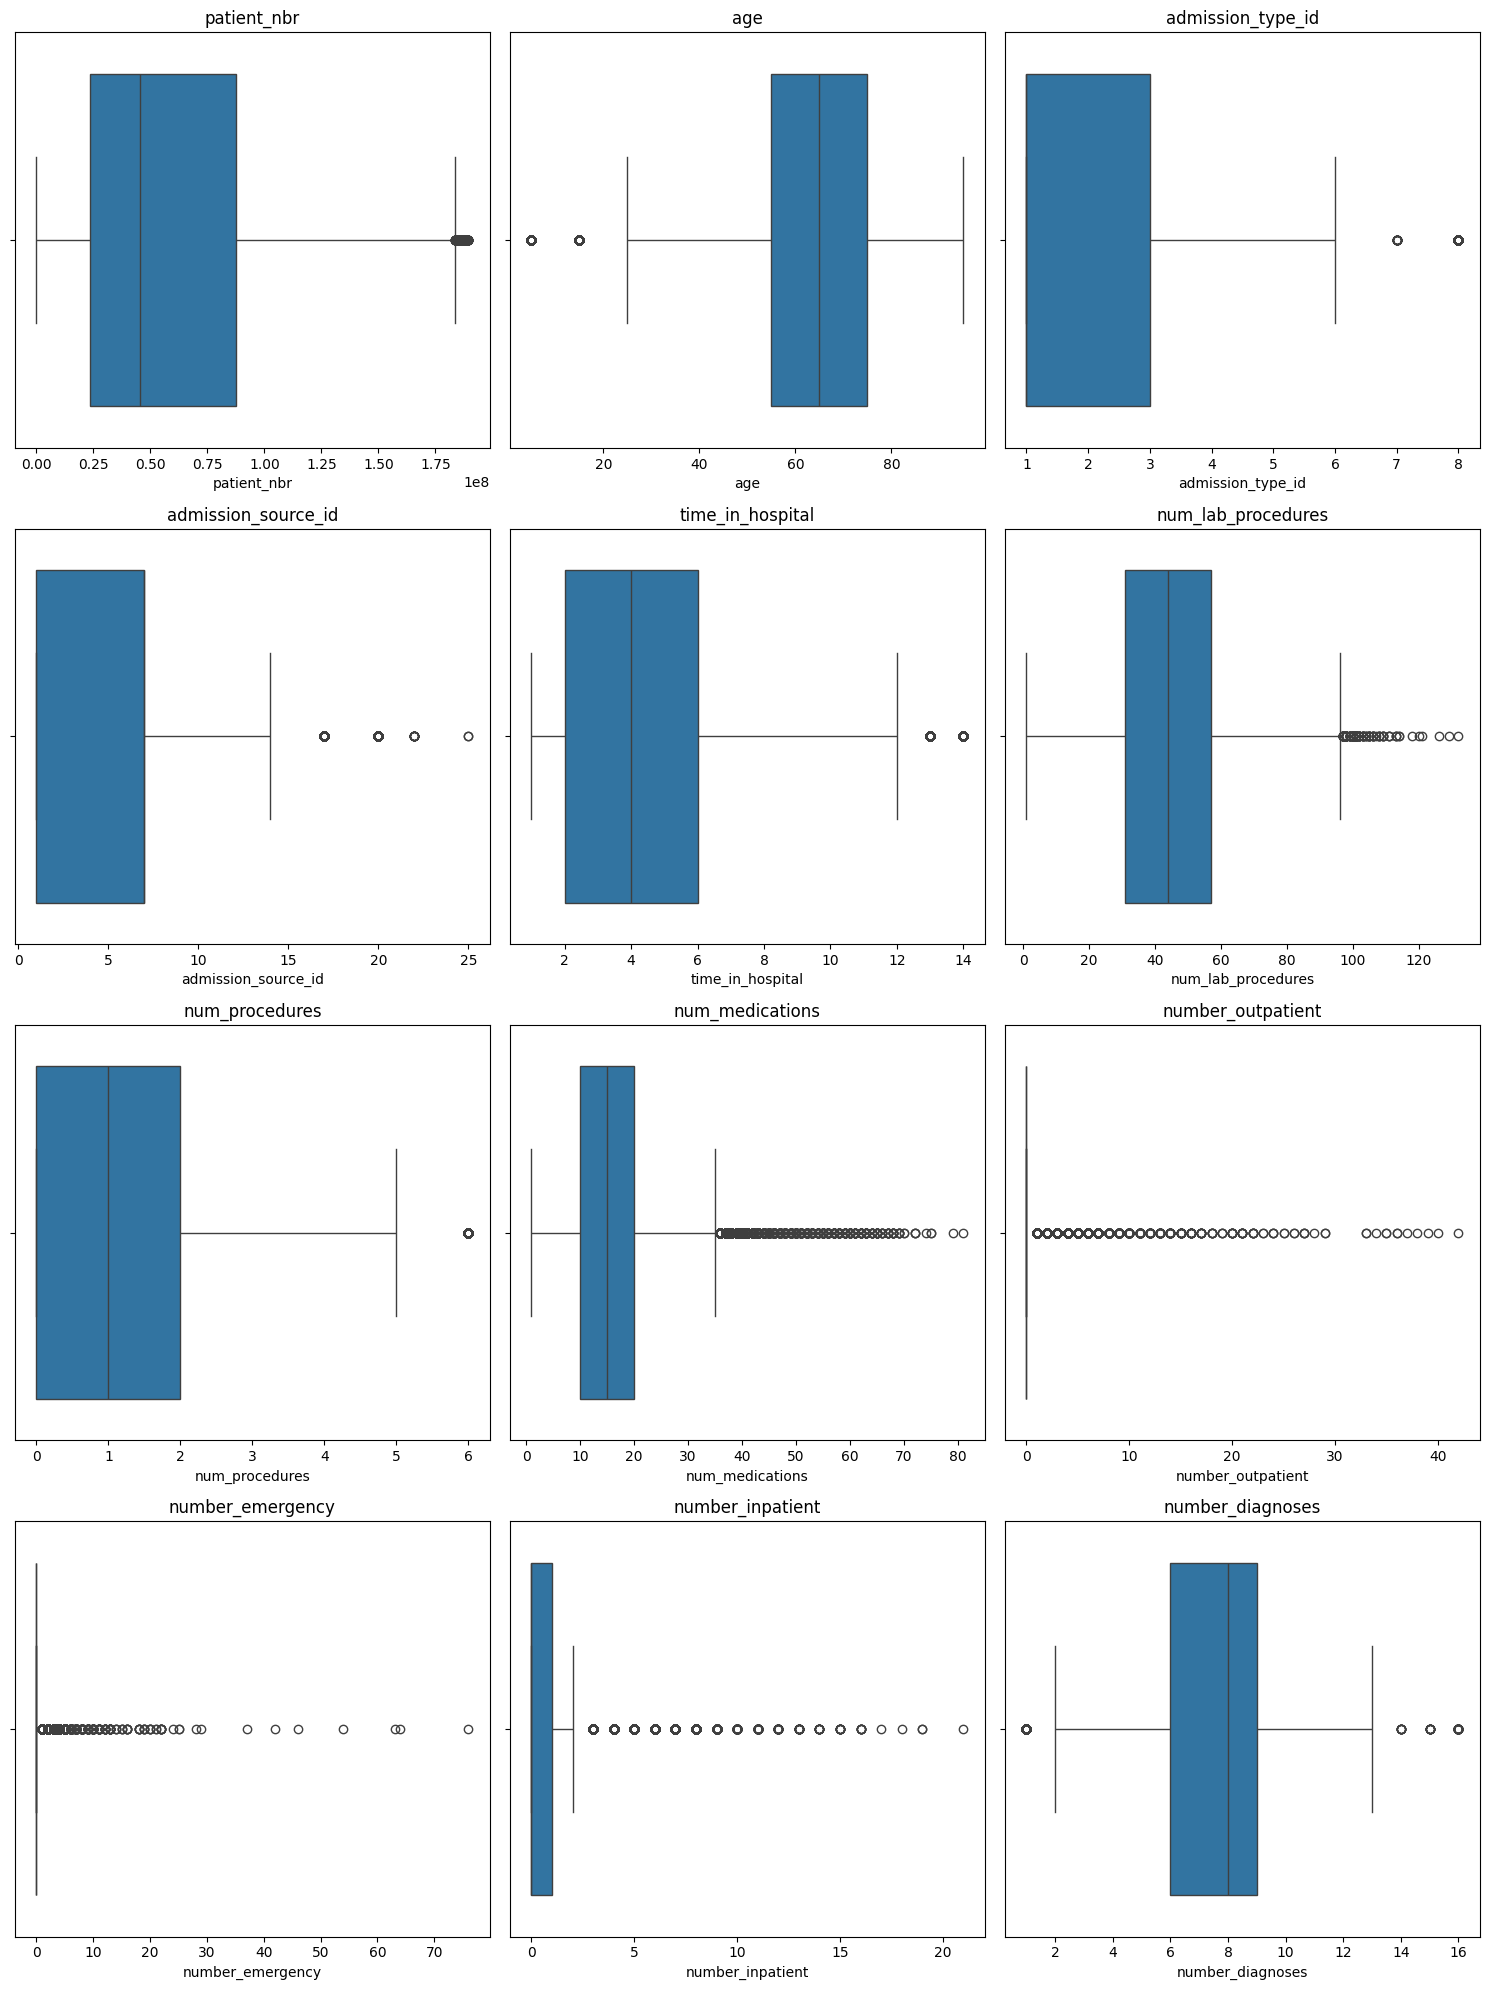

In [136]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

cols_per_row = 3
rows = (len(num_cols) + cols_per_row - 1) // cols_per_row

plt.figure(figsize=(15, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols_per_row, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Boxplots were used to visually inspect the distribution of each numerical feature and identify extreme values. Several features, particularly those related to patient visits such as `number_inpatient`, `number_outpatient`, and `number_emergency`, showed right-skewed distributions with noticeable outliers.

These outliers are likely to represent real-world medical conditions, such as patients with frequent hospital visits, and therefore were analyzed carefully before deciding on appropriate handling techniques.

### Handling Skewed Data

Instead of removing or aggressively capping outliers, log transformation was applied to highly skewed numerical features such as `number_inpatient`, `number_outpatient`, and `number_emergency`.

This approach reduces the impact of extreme values while preserving important medical information, ensuring better model performance without losing critical data.

In [137]:
cols_to_transform = ['number_inpatient', 'number_outpatient', 'number_emergency']

for col in cols_to_transform:
    df[col] = np.log1p(df[col])

For other numerical features such as time_in_hospital, num_lab_procedures, and num_medications, transformation was not applied because their distributions were relatively balanced and in some feature outliers carry important information. Applying transformation on such features could distort their natural patterns and negatively affect model interpretability.

Thus, transformation was selectively applied only where necessary to maintain a balance between data integrity and model performance.

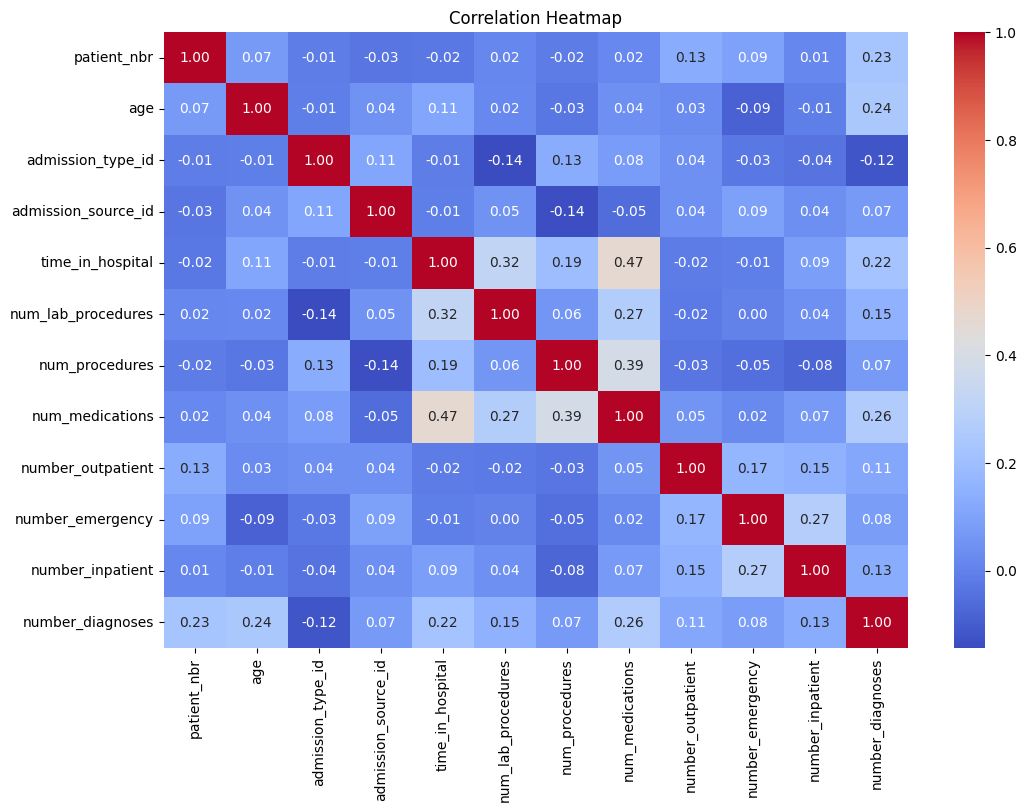

In [138]:
import seaborn as sns
corr = df[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

### Correlation Heatmap Analysis

The heatmap shows the correlation between numerical features in the dataset. Most features have low to moderate correlation with each other, indicating minimal multicollinearity.

Some moderate positive correlations can be observed, such as between *num_medications* and *num_lab_procedures*, as well as *number_inpatient* and *number_emergency*. These relationships suggest that patients with more medical interactions tend to undergo more procedures.

Overall, no strong correlations are present, which is beneficial for model performance as it reduces redundancy among features.

## Fixing target variable

##### The readmitted column in the dataset contains three categories: <30, >30, and NO.


##### - <30 indicates that the patient was readmitted to the hospital within 30 days.
##### - >30 indicates that the patient was readmitted after 30 days.
##### - NO indicates that the patient was not readmitted.


##### For this project, the target variable was converted into a binary classification problem. Patients who were readmitted within 30 days (<30) 

##### were labeled as 1, because early readmission is considered a high-risk case. Patients who were readmitted after 30 days (>30) and those who

##### were not readmitted (NO) were labeled as 0, as they are considered lower risk compared to early readmission cases.

##### This conversion helps the machine learning model to classify whether a patient is likely to be readmitted within 30 days or not.

In [139]:
# Check original target distribution
print("Original readmission distribution:")
print(df['readmitted'].value_counts())

print("\nPercentage distribution:")
print(df['readmitted'].value_counts(normalize=True) * 100)


# Create binary target: 30-day readmission
df['target'] = (df['readmitted'] == '<30').astype(int)

print("\nBinary target distribution:")
print(df['target'].value_counts())

print("\nBinary target percentage:")
print(df['target'].value_counts(normalize=True) * 100)

Original readmission distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Percentage distribution:
readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

Binary target distribution:
target
0    90409
1    11357
Name: count, dtype: int64

Binary target percentage:
target
0    88.840084
1    11.159916
Name: proportion, dtype: float64


In [140]:
df['readmitted'] = df['readmitted'].map({
    '<30': 1,
    '>30': 0,
    'NO': 0
})

## Feature Transformation

#### We apply Top-N Grouping which is like one type of encoding

### High Cardinality Issue in Diagnosis Features

However, some features such as `diag_1`, `diag_2`, and `diag_3` have very high cardinality, meaning they contain a large number of unique diagnosis codes. Applying One-Hot Encoding directly on these columns would result in a significant increase in the number of features, leading to higher model complexity, increased training time, and potential overfitting.

### Solution: Categorization of Diagnosis Codes

To address this issue, the diagnosis codes were grouped into broader medical categories (such as circulatory, respiratory, digestive, and diabetes), which helped reduce dimensionality while preserving meaningful information. The original diagnosis columns were then removed, and One-Hot Encoding was applied to the remaining categorical features.

### Outcome

This approach ensured a balanced feature set, improved model efficiency, and maintained important medical insights for predicting patient readmission.

In [141]:
def categorize_diag(code):
    try:
        code = float(code)
        if 390 <= code <= 459:
            return 'Circulatory'
        elif 460 <= code <= 519:
            return 'Respiratory'
        elif 520 <= code <= 579:
            return 'Digestive'
        elif 250 <= code < 251:
            return 'Diabetes'
        else:
            return 'Other'
    except:
        return 'Other'

df['diag_1_cat'] = df['diag_1'].apply(categorize_diag)
df['diag_2_cat'] = df['diag_2'].apply(categorize_diag)
df['diag_3_cat'] = df['diag_3'].apply(categorize_diag)

df.drop(['diag_1', 'diag_2', 'diag_3'], axis=1, inplace=True)

The columns `admission_type_id` and `admission_source_id` originally contained numerical codes representing different categories. These codes were mapped to meaningful categorical labels to improve interpretability.

Further, the `admission_source` feature had a high number of categories, which could increase model complexity after encoding. To address this, similar categories were grouped into broader classes such as *Emergency*, *Referral*, *Transfer*, *Delivery*, and *Other*. This helped reduce dimensionality while preserving important information.

Finally, the original ID columns were dropped as they were no longer required, avoiding redundancy in the dataset.

In [142]:
admission_type_map = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available",
    6: "Unknown",
    7: "Trauma Center",
    8: "Not Mapped"
}

df['admission_type'] = df['admission_type_id'].map(admission_type_map)

In [143]:
admission_source_map = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from Hospital",
    5: "Transfer from Skilled Nursing",
    6: "Transfer from Health Care Facility",
    7: "Emergency Room",
    8: "Court/Law Enforcement",
    9: "Not Available",
    10: "Transfer from Critical Access Hospital",
    11: "Normal Delivery",
    12: "Premature Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    15: "Not Available",
    17: "Unknown",
    18: "Transfer from Another Home"
}

df['admission_source'] = df['admission_source_id'].map(admission_source_map)

def simplify_admission_source(x):
    if x in ['Emergency Room']:
        return 'Emergency'
    elif x in ['Physician Referral', 'Clinic Referral', 'HMO Referral']:
        return 'Referral'
    elif 'Transfer' in str(x):
        return 'Transfer'
    elif x in ['Normal Delivery', 'Premature Delivery', 'Sick Baby']:
        return 'Delivery'
    else:
        return 'Other'

df['admission_source'] = df['admission_source'].apply(simplify_admission_source)

df = df.drop(columns=['admission_type_id', 'admission_source_id'])

### Reason for Feature Transformation Before Encoding

Feature transformation was applied before encoding to handle high-cardinality categorical features such as diagnosis codes (`diag_1`, `diag_2`, `diag_3`) and admission-related variables.

These columns originally contained a large number of unique values, which would significantly increase the number of features after applying One-Hot Encoding. This can lead to increased model complexity, higher computational cost, and a greater risk of overfitting.

To address this, the diagnosis codes were grouped into broader medical categories, and admission-related features were simplified into meaningful groups. This reduced the number of unique categories while preserving important domain-specific information.

By performing this transformation before encoding, the dataset becomes more manageable, efficient for model training, and less prone to the curse of dimensionality.


### Feature and Target Separation

The dataset was divided into features (X) and target variable (y), where X contains all input variables and y represents the output to be predicted (`readmitted`).

This separation is necessary for training machine learning models, as it allows the model to learn patterns from the input features and predict the target variable. It also helps prevent data leakage and ensures proper model evaluation.

In [144]:
X = df.drop('readmitted', axis=1)
y = df['readmitted']

In [145]:
new_num_cols = X.select_dtypes(include=['int64', 'float64']).columns

In [146]:
print("Total rows:", len(df))
print("Unique patients:", df['patient_nbr'].nunique())

patient_counts = df['patient_nbr'].value_counts()

print("\nDuplicate patient records:")
print(len(df) - df['patient_nbr'].nunique())

multi_visit_patients = (patient_counts > 1).sum()

print("\nPatients with multiple encounters:")
print(multi_visit_patients)

print("\nPercentage of patients with multiple encounters:")
print(round(multi_visit_patients / len(patient_counts) * 100, 2), "%")

print("\nPatient encounter statistics:")
print(patient_counts.describe())

Total rows: 101766
Unique patients: 71518

Duplicate patient records:
30248

Patients with multiple encounters:
16773

Percentage of patients with multiple encounters:
23.45 %

Patient encounter statistics:
count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64


In [147]:
import numpy as np

# Total healthcare utilization
df['total_previous_visits'] = (
    df['number_outpatient']
    + df['number_emergency']
    + df['number_inpatient']
)

# Total clinical procedures
df['total_procedures'] = (
    df['num_lab_procedures']
    + df['num_procedures']
)

# Medication intensity per hospital day
df['medications_per_day'] = (
    df['num_medications']
    / df['time_in_hospital'].replace(0, 1)
)

# Procedure intensity per hospital day
df['procedures_per_day'] = (
    df['num_procedures']
    / df['time_in_hospital'].replace(0, 1)
)

# Lab intensity per hospital day
df['labs_per_day'] = (
    df['num_lab_procedures']
    / df['time_in_hospital'].replace(0, 1)
)

# Emergency utilization indicator
df['has_emergency_visit'] = (
    df['number_emergency'] > 0
).astype(int)

# Previous inpatient history indicator
df['has_previous_inpatient'] = (
    df['number_inpatient'] > 0
).astype(int)

In [148]:
new_features = [
    'total_previous_visits',
    'total_procedures',
    'medications_per_day',
    'procedures_per_day',
    'labs_per_day',
    'has_emergency_visit',
    'has_previous_inpatient'
]

print(df[new_features].describe())

       total_previous_visits  total_procedures  medications_per_day  \
count          101766.000000     101766.000000        101766.000000   
mean                0.600362         44.435371             5.074465   
std                 0.863309         19.846605             3.826038   
min                 0.000000          1.000000             0.083333   
25%                 0.000000         33.000000             2.600000   
50%                 0.000000         45.000000             4.000000   
75%                 1.098612         58.000000             6.166667   
max                 7.049255        135.000000            42.000000   

       procedures_per_day   labs_per_day  has_emergency_visit  \
count       101766.000000  101766.000000        101766.000000   
mean             0.452709      14.381453             0.111855   
std              0.872380      12.060457             0.315189   
min              0.000000       0.071429             0.000000   
25%              0.000000       6.5

In [149]:
# Train-Test-Split
from sklearn.model_selection import GroupShuffleSplit

# Separate target
y = df['target']

# Keep patient_nbr only for grouping
groups = df['patient_nbr']

# Features (temporarily still containing patient_nbr)
X = df.drop(columns=['target', 'readmitted'])

# Group-based split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

In [150]:
train_patients = set(X_train['patient_nbr'])
test_patients = set(X_test['patient_nbr'])

overlap = train_patients.intersection(test_patients)

print("Patients in training:", len(train_patients))
print("Patients in testing:", len(test_patients))
print("Patient overlap:", len(overlap))

Patients in training: 57214
Patients in testing: 14304
Patient overlap: 0


In [151]:
X_train.drop(columns=['patient_nbr'], inplace=True)
X_test.drop(columns=['patient_nbr'], inplace=True)

In [152]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'total_previous_visits', 'total_procedures', 'medications_per_day', 'procedures_per_day', 'labs_per_day', 'has_emergency_visit', 'has_previous_inpatient']

Categorical Features:
['race', 'gender', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'diag_1_cat', 'diag_2_cat', 'diag_3_cat', 'admission_type', 'admission_source']

Number of Numerical Features: 16
Number of Categorical Features: 30


In [153]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import numpy as np


# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)


# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)


# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same transformation to test data
X_test_processed = preprocessor.transform(X_test)


print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("\nOriginal X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

print("\nMissing values in processed training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in processed testing data:",
      np.isnan(X_test_processed).sum())

Original X_train shape: (81613, 46)
Processed X_train shape: (81613, 121)

Original X_test shape: (20153, 46)
Processed X_test shape: (20153, 121)

Missing values in processed training data: 0
Missing values in processed testing data: 0


#### Multicollinearity Analysis Using VIF

In [154]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X_train[numerical_features].sample(n=5000, random_state=42).dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

high_vif_features = vif_data[vif_data["VIF"] > 10]["feature"].tolist()

print("Features with VIF > 10:")
print(high_vif_features)


Variance Inflation Factor (VIF) was used to analyze multicollinearity among the features. Several features showed very high or infinite VIF values, indicating strong linear relationships.

This behavior is expected in datasets with one-hot encoded categorical variables, where multiple columns represent different categories of the same feature and are inherently dependent.

Instead of removing a large number of features, multicollinearity was handled using regularization techniques in Logistic Regression, which reduces the impact of correlated features without losing important information.

Additionally, we can use tree-based models such as Random Forest and XGBoost were used, which are not affected by multicollinearity.

### t-SNE Visualization

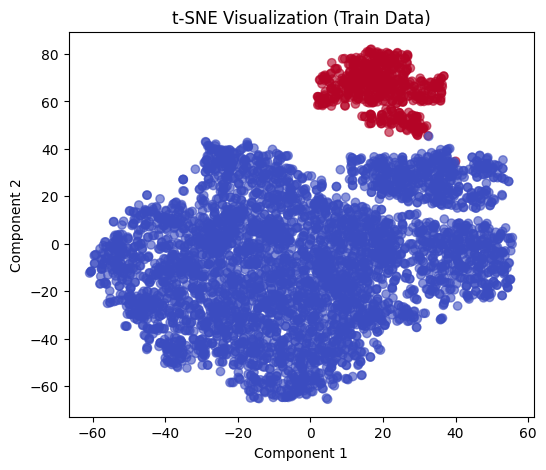

In [35]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Use TRAIN scaled data
X_sample = X_train_processed[:5000]
y_sample = y_train[:5000]

tsne = TSNE(n_components=2, random_state=42)

X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(6,5))
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=y_sample, cmap='coolwarm', alpha=0.6)
plt.title("t-SNE Visualization (Train Data)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()


t-SNE was used to reduce the high-dimensional dataset into two dimensions for visualization. Each point represents a data sample, colored based on its class label.

The visualization shows significant overlap between the two classes, indicating that the data is not clearly separable. This explains the moderate performance of the classification models, as distinguishing between classes becomes challenging when they are closely mixed.

Additionally, the minority class is scattered within the majority class, which further highlights the difficulty of identifying positive cases and justifies the use of techniques like SMOTE and threshold tuning.


### Applying UMAP

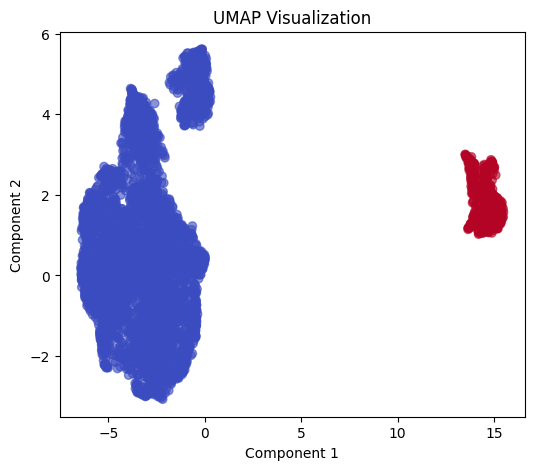

In [36]:
import umap.umap_ as umap

reducer = umap.UMAP(n_components=2, random_state=42)

X_umap = reducer.fit_transform(X_sample)

plt.figure(figsize=(6,5))
plt.scatter(X_umap[:,0], X_umap[:,1], c=y_sample, cmap='coolwarm', alpha=0.6)
plt.title("UMAP Visualization")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

### UMAP Visualization

UMAP was used to visualize the high-dimensional data in two dimensions while preserving both local and global structure. Compared to t-SNE, UMAP shows more defined clusters, indicating some underlying structure in the dataset.

However, there is still significant overlap between the classes, with the minority class distributed across the majority class clusters. This suggests that the data is not perfectly separable, which explains the moderate performance of the classification models.

The presence of partially distinct clusters indicates that while patterns exist, they are not strong enough for clear classification, justifying the need for techniques such as SMOTE and threshold tuning.


### Dimensionality Reduction using t-SNE and UMAP

t-SNE and UMAP were used to visualize high-dimensional data in two dimensions. These techniques help in understanding the underlying structure and class distribution.

t-SNE focuses on preserving local relationships, while UMAP provides faster computation and better global structure representation. The visualizations indicate that the classes are partially overlapping, which explains the moderate performance of the models.